# 01 GW map: the localisation on the analysis grid

`uuls.gwmap` puts an alert skymap (sky probability and the distance ansatz per HEALPix pixel)
on the WCS image geometry of the gamma-ray analysis. `uuls.gwpe` reads the standardized
parameter-estimation samples of the same event. This notebook shows what both return for
S240615dg and the checks behind them.

What `gwmap.on_geom` computes, per WCS bin $b$:

- $p_b$: mean probability density over the bin times its solid angle. The mean is over an
  $8\times 8$ grid of points inside the bin, so multi-order maps need no rasterisation.
- mask: the bin centre lies in the greedy credible region (default 95%).
- $F_b(r)$: the distance CDF, the density-weighted mixture of the pixel ansatz CDFs
  (Singer et al. 2016) on a grid starting at 1 Mpc.

Inputs

- skymap `data/gw/skymaps/S240615dg.fits` (multi-order, LVK alert)
- PE samples `data/gw/pe_standardized/S240615dg.h5`
- geom: 6 x 6 deg, AIR, 0.2 deg bins, centred on (7.7, 45.7) deg
- `credible = 0.95`, `r_grid` default (1 to 10000 Mpc, 1000 points)
- cache: `cache/gwmap/<key>` (key printed below)

Imports, and the figure saver for this notebook.

In [1]:
import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")

import numpy as np
import matplotlib.pyplot as plt
import astropy_healpix as ah
from astropy.coordinates import SkyCoord
from gammapy.maps import WcsGeom
from ligo.skymap.distance import marginal_pdf

from uuls import gwmap, gwpe, paths, cache
from uuls.figures import FigureSaver, COLORS

figs = FigureSaver("0_tools", "01_gw_map")
SKYMAP = paths.GW_SKYMAPS / "S240615dg.fits"
EVENT = "S240615dg"

The skymap as read. `t0` is the merger time from the header; it is the time origin of every
light curve downstream. The credible areas use the same greedy ordering as the mask.

In [2]:
sky = gwmap.read_healpix(SKYMAP)
orders = np.log2(sky.nside).astype(int)
print(f"{sky.name}: t0 = {sky.t0.isot} UTC, {len(sky.prob)} pixels, orders {orders.min()}-{orders.max()}")
print(f"total probability {sky.prob.sum():.6f}")
for c in (0.5, 0.9, 0.95):
    print(f"{c:.0%} area: {gwmap.credible_area_deg2(SKYMAP, c):.2f} deg2")

S240615dg: t0 = 2024-06-15T11:36:20.729 UTC, 21504 pixels, orders 4-12
total probability 1.000000
50% area: 1.49 deg2
90% area: 5.11 deg2
95% area: 6.64 deg2


The analysis geometry. It is small on purpose: the 95% region covers 6.6 deg2, so a 6 deg
square around the maximum holds all of it. The result is cached; the key depends on the skymap
file, the WCS header, `credible`, `r_grid` and the code version.

In [3]:
geom = WcsGeom.create(skydir=(7.7, 45.7), width=6.0, binsz=0.2, frame="icrs", proj="AIR")
gw = gwmap.on_geom(SKYMAP, geom, credible=0.95)
params = {"skymap": SKYMAP, "geom": gwmap.geom_params(geom), "credible": 0.95,
          "r_grid": gw.r_grid, "oversample": gwmap.OVERSAMPLE, "version": gwmap.VERSION}
print("cache key: gwmap/" + cache.key(params))
print(f"grid {gw.prob.shape}, sum p_b = {gw.prob.sum():.5f}, bins in mask {gw.mask.sum()}, "
      f"valid distance CDFs {gw.cdf_valid.sum()}")

[cache] gwmap/d2f183f611ff: loaded
cache key: gwmap/d2f183f611ff
grid (30, 30), sum p_b = 1.00002, bins in mask 166, valid distance CDFs 898


For the contours, each bin centre gets the credible level of the HEALPix pixel under it; the
50, 90 and 95% lines are contours of that image.

In [4]:
ra_c, dec_c = (c.value for c in gw.geom.get_coord(mode="center")[:2])
levels_img = gwmap.credible_levels(sky)[sky.lookup(ra_c, dec_c)]

def sky_axes(fig):
    ax = fig.add_subplot(111, projection=gw.geom.wcs)
    ax.coords[0].set_axislabel("RA")
    ax.coords[1].set_axislabel("Dec")
    return ax

def contours(ax, color="w"):
    cs = ax.contour(levels_img, levels=[0.5, 0.9, 0.95], colors=color, linewidths=[1.4, 1.0, 0.7])
    ax.clabel(cs, fmt=lambda v: f"{v:.0%}", fontsize=8)

The bin probability $p_b$ with the credible contours.

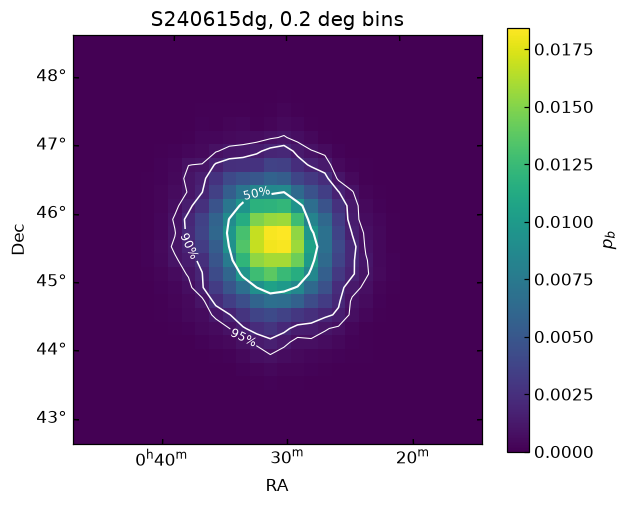

In [5]:
fig = plt.figure(figsize=(6, 5))
ax = sky_axes(fig)
im = ax.imshow(gw.prob, origin="lower")
contours(ax)
fig.colorbar(im, ax=ax, label="$p_b$")
ax.set_title(f"{gw.name}, {gw.geom.pixel_scales[0].deg:.1f} deg bins")
figs.save(fig, "prob_on_geom")
plt.show()

The 95% mask. Bins enter whole, by their centre, so the probability inside the mask is close
to but not exactly 0.95: the boundary bins are either fully in or fully out.

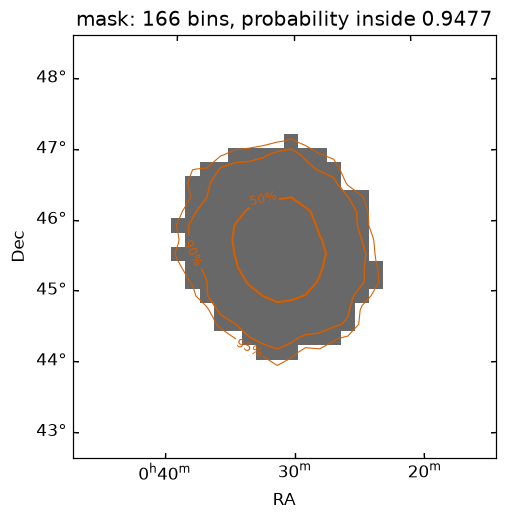

In [6]:
fig = plt.figure(figsize=(6, 5))
ax = sky_axes(fig)
ax.imshow(gw.mask, origin="lower", cmap="Greys", vmin=0, vmax=1.5)
contours(ax, color=COLORS[3])
ax.set_title(f"mask: {gw.mask.sum()} bins, probability inside {gw.prob[gw.mask].sum():.4f}")
figs.save(fig, "mask")
plt.show()

Total probability on the grid against the plain HEALPix sum of the pixels whose centre falls in
the geom. They should agree to the integration error at the geom border.

In [7]:
level, ipix = ah.uniq_to_level_ipix(sky.uniq)
lon, lat = np.empty(len(ipix)), np.empty(len(ipix))
for lv in np.unique(level):
    s = level == lv
    lo, la = ah.healpix_to_lonlat(ipix[s], ah.level_to_nside(lv), order="nested")
    lon[s], lat[s] = lo.deg, la.deg
inside = gw.geom.contains(SkyCoord(lon, lat, unit="deg"))
print(f"sum p_b = {gw.prob.sum():.5f}, HEALPix sum inside the geom = {sky.prob[inside].sum():.5f}")

sum p_b = 1.00002, HEALPix sum inside the geom = 1.00000


Distance CDF of four bins: the maximum, and bins at the 50, 90 and 95% credible levels.

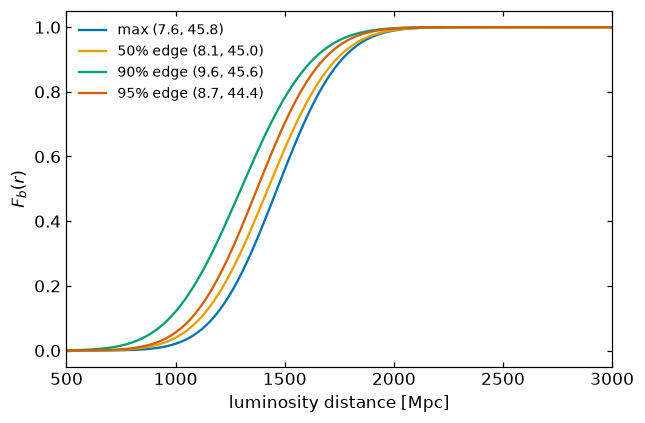

In [8]:
picks = {"max": np.unravel_index(np.argmax(gw.prob), gw.prob.shape)}
for c in (0.5, 0.9, 0.95):
    picks[f"{c:.0%} edge"] = np.unravel_index(np.argmin(np.abs(levels_img - c)), levels_img.shape)

fig, ax = plt.subplots()
for (label, (iy, ix)), col in zip(picks.items(), COLORS):
    ax.plot(gw.r_grid, gw.cdf[iy, ix], color=col,
            label=f"{label} ({ra_c[iy, ix]:.1f}, {dec_c[iy, ix]:.1f})")
ax.set_xlim(500, 3000)
ax.set_xlabel("luminosity distance [Mpc]")
ax.set_ylabel("$F_b(r)$")
ax.legend(fontsize=9)
figs.save(fig, "cdf_bins")
plt.show()

The distance distribution marginalised over the grid, $\sum_b p_b\,F_b(r) / \sum_b p_b$,
against the HEALPix one, `ligo.skymap.distance.marginal_pdf` over all pixels. The grid holds
all but a negligible part of the probability, so the two must overlap. The PE samples are shown
too: the alert skymap and the catalog PE are different analyses and need not agree.

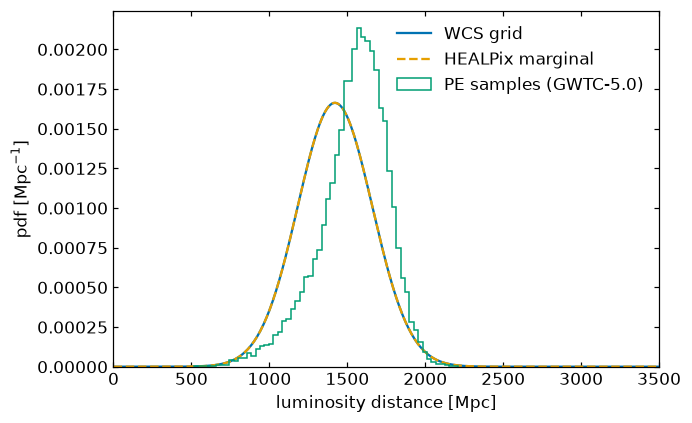

max |pdf_grid - pdf_hp| / max pdf_hp = 0.0003
median distance: grid 1421 Mpc, PE 1566 Mpc


In [9]:
r = gw.r_grid
w = np.where(gw.cdf_valid, gw.prob, 0.0)
cdf_grid = np.tensordot(w, gw.cdf, axes=([0, 1], [0, 1])) / w.sum()
pdf_grid = np.gradient(cdf_grid, r)
good = np.isfinite(sky.distmu)
pdf_hp = marginal_pdf(r, sky.prob[good] / sky.prob[good].sum(), sky.distmu[good],
                      sky.distsigma[good], sky.distnorm[good])
samples = gwpe.load_samples(EVENT)

fig, ax = plt.subplots()
ax.plot(r, pdf_grid, label="WCS grid")
ax.plot(r, pdf_hp, ls="--", label="HEALPix marginal")
ax.hist(samples["luminosity_distance"], bins=60, density=True, histtype="step",
        color=COLORS[2], label="PE samples (GWTC-5.0)")
ax.set_xlim(0, 3500)
ax.set_xlabel("luminosity distance [Mpc]")
ax.set_ylabel("pdf [Mpc$^{-1}$]")
ax.legend()
figs.save(fig, "distance_marginal")
plt.show()
print(f"max |pdf_grid - pdf_hp| / max pdf_hp = {np.abs(pdf_grid - pdf_hp).max() / pdf_hp.max():.4f}")
print(f"median distance: grid {np.interp(0.5, cdf_grid, r):.0f} Mpc, "
      f"PE {np.median(samples['luminosity_distance']):.0f} Mpc")

Regression against the old code (`tests/test_gwmap.py::test_regression_against_gwuls`). Both
are run on the same input, the skymap rasterised to nside 512, and the same 0.2 deg grid. The old
`integrate_hp_on_wcs` assigns each pixel to one bin through an (RA, Dec) box and scales the
mean of the few pixels per bin to the bin area. Against an exact reference (nside 4096
sub-pixels summed per bin) its per-bin error is 5% (median) and $\sum_b |\Delta p_b| = 0.054$;
the new integration gives 1.4% and 0.018. The two codes agree on the total within 0.3%, on the
95% mask up to 8 boundary bins, and on the median distance per bin within 1.3%.

The PE samples on the sky, over the grid probability. A sample is one possible source, with
position, distance and inclination drawn together, which is how the model limits use them.

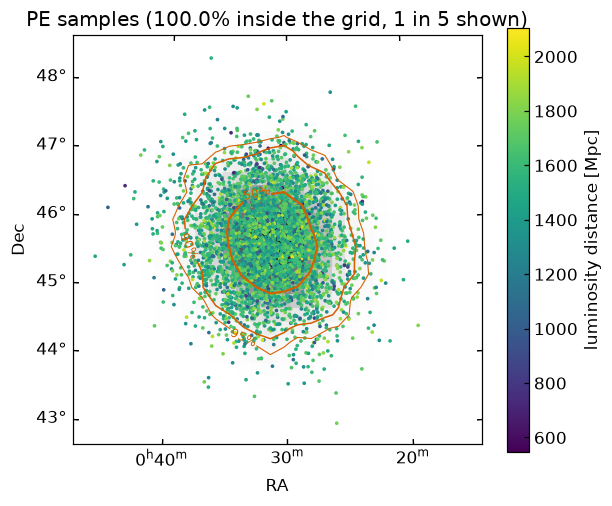

In [10]:
in_grid = gw.geom.contains(SkyCoord(samples["ra"], samples["dec"], unit="deg"))
fig = plt.figure(figsize=(6, 5))
ax = sky_axes(fig)
ax.imshow(gw.prob, origin="lower", cmap="Greys")
contours(ax, color=COLORS[3])
sub = samples[in_grid][::5]
sc = ax.scatter(sub["ra"], sub["dec"], s=2, c=sub["luminosity_distance"], cmap="viridis",
                transform=ax.get_transform("icrs"))
fig.colorbar(sc, ax=ax, label="luminosity distance [Mpc]")
ax.set_title(f"PE samples ({in_grid.mean():.1%} inside the grid, 1 in 5 shown)")
figs.save(fig, "pe_on_sky")
plt.show()

The jet viewing angle $\theta_v = \min(\theta_{JN}, 180° - \theta_{JN})$, over all samples and
in three distance terciles. The GW amplitude falls with distance and with inclination, so
the two are degenerate: in the posterior the far samples are the face-on ones. This is why
distance and angle are drawn together, from the same sample.

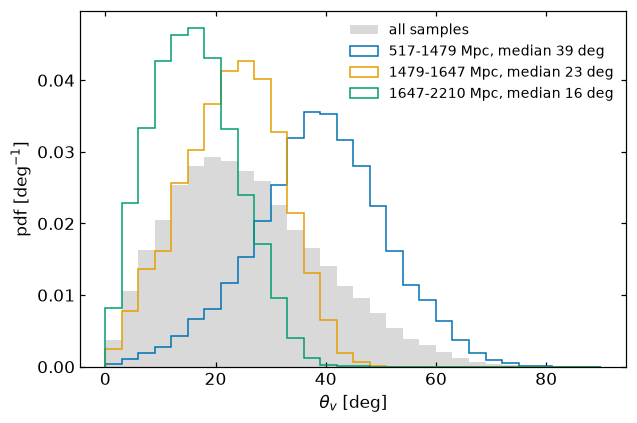

P(theta_v < 30 deg) = 0.647


In [11]:
d_edges = np.percentile(samples["luminosity_distance"], [0, 33.3, 66.7, 100]) + [0, 0, 0, 1]
bins = np.linspace(0, 90, 31)
fig, ax = plt.subplots()
ax.hist(samples["theta_v"], bins=bins, density=True, histtype="stepfilled", color="0.85",
        label="all samples")
for k, (part, col) in enumerate(zip(gwpe.theta_v_given_distance(samples, d_edges), COLORS)):
    ax.hist(part, bins=bins, density=True, histtype="step", color=col,
            label=f"{d_edges[k]:.0f}-{d_edges[k + 1]:.0f} Mpc, median {np.median(part):.0f} deg")
ax.set_xlabel(r"$\theta_v$ [deg]")
ax.set_ylabel("pdf [deg$^{-1}$]")
ax.legend(fontsize=9)
figs.save(fig, "theta_v")
plt.show()
print(f"P(theta_v < 30 deg) = {np.mean(samples['theta_v'] < 30):.3f}")

Outputs

- cache entry `cache/gwmap/<key>` (key printed above): the `GWMap` of S240615dg on the 6 deg,
  0.2 deg grid
- figures in `outputs/figures/0_tools/01_gw_map/`: `prob_on_geom`, `mask`, `cdf_bins`,
  `distance_marginal`, `pe_on_sky`, `theta_v` (png and pdf)